# Baum et al.: space-time verification

This notebook reproduces the Qva and Qtb one-column reference cases from Baum, Godt, and Savage (2010). The calculated pressure and factor-of-safety (FS) figure is followed by a separate image output embedding **Figure 10 from Baum et al. (2010)** from `docs/assets`.

This is **code-to-reference verification**, not field validation: the comparison checks whether the implementation reproduces published profiles. The TRIGRS trajectories are retained as a raster because the reference curves are not available here as machine-readable values.

This notebook uses `equation_set="baum_etal"` for comparison with the TRIGRS-style formulation. The default `"srivastava_yeh"` formulation gives different pressure, moisture, and stability on a slope. See the [equation comparison](/unsatstab/fundamentals/#pressure-and-water-content-equation-sets).


## Cases and inputs

Both cases use constant rainfall of 4.5 mm/h for 24 h, below saturated conductivity $K_{\mathrm{s}}$ for both soils. Qva represents the efficiently draining end member; Qtb uses a restrictive finite basal boundary. The material and geometry vary between cases as reported in the published example.

| Case | Slope | Column/observation depth | $K_{\mathrm{s}}$ | $\alpha$ | Boundary |
|---|---:|---:|---:|---:|---|
| Qva | 45° | 0.83 m | $5.0\times10^{-5}\;\mathrm{m/s}$ | 3.5 m⁻¹ | Infinite drainage |
| Qtb | 40° | 1.01 m | $1.0\times10^{-5}\;\mathrm{m/s}$ | 3.0 m⁻¹ | Finite perched |

The time profiles are sampled at 0, 2, 8, 16, and 24 h. Color represents elapsed time and is shared by pressure-head and factor-of-safety panels.

See [flow response](/unsatstab/fundamentals/#unsaturated-flow-response), [stability](/unsatstab/fundamentals/#infinite-slope-stability), and [equation provenance](/unsatstab/fundamentals/#equation-provenance) for the formulas and adaptations used here.

These reference runs use the same maximum column depth, initial water table, and observation depth. The solver defaults the observation plane to the base; the full-column profiles are retained.


In [1]:
%matplotlib inline
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import tol_colors as tc
import unsatstab as us

mpl.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 8.5,
    "mathtext.fontset": "dejavuserif",
    "axes.titlesize": 9,
    "axes.labelsize": 8.5,
    "axes.linewidth": 1.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "axes.grid": False,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "legend.frameon": False,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
})
COLORS = tc.colorsets["bright"]
TIME_CMAP = tc.colormaps["rainbow_PuBr"]

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "unsatstab").is_dir())
ASSET_DIR = REPO / "docs" / "assets"

from IPython.display import Image, Markdown, display


In [2]:
strength = us.StrengthProperties(
    cohesion=3_000.0,
    friction_angle_deg=33.6,
    unit_weight_soil=18_000.0,
    max_factor_of_safety=10.0,
)
output_times_h = np.arange(25.0)
rainfall = us.RainfallSeries.constant(4.5, 24.0)

def run_case(name, slope_deg, depth_m, ks_m_s, alpha_m_inv, boundary):
    hydro = us.HydraulicProperties(
        equation_set="baum_etal",
        slope_angle_deg=slope_deg,
        maximum_depth=depth_m,
        saturated_hydraulic_conductivity=ks_m_s,
        alpha=alpha_m_inv,
        theta_s=0.41,
        theta_r=0.06,
        long_term_infiltration=1.5e-7,
        n_roots=120,
        n_depths=50,
    )
    result = us.run_single_column(
        hydro=hydro,
        rainfall=rainfall,
        strength=strength,
        boundary=boundary,
        output_times=output_times_h,
    )
    return {"name": name, "depth_m": depth_m, "result": result}

cases = [
    run_case("Qva", 45.0, 0.83, 5.0e-5, 3.5, us.InfiniteDrainageBoundary()),
    run_case("Qtb", 40.0, 1.01, 1.0e-5, 3.0, us.FinitePerchedBoundary()),
]
selected_hours = np.array([0.0, 2.0, 8.0, 16.0, 24.0])
selected_colors = TIME_CMAP(np.linspace(0.05, 0.95, len(selected_hours)))


## Compare model output with Figure 10

Pressure head becomes less negative as infiltration wets the profile. Factor of safety responds to the evolving pressure and water content; the horizontal guide marks $\mathrm{FS}=1$, while the dashed depth guide marks the selected failure plane. The lower row has a different depth range because the Qtb failure plane is deeper.

The computed figure is followed by the supplied Figure 10 in a separate text cell. The published curves are retained as a raster, without re-digitizing them.

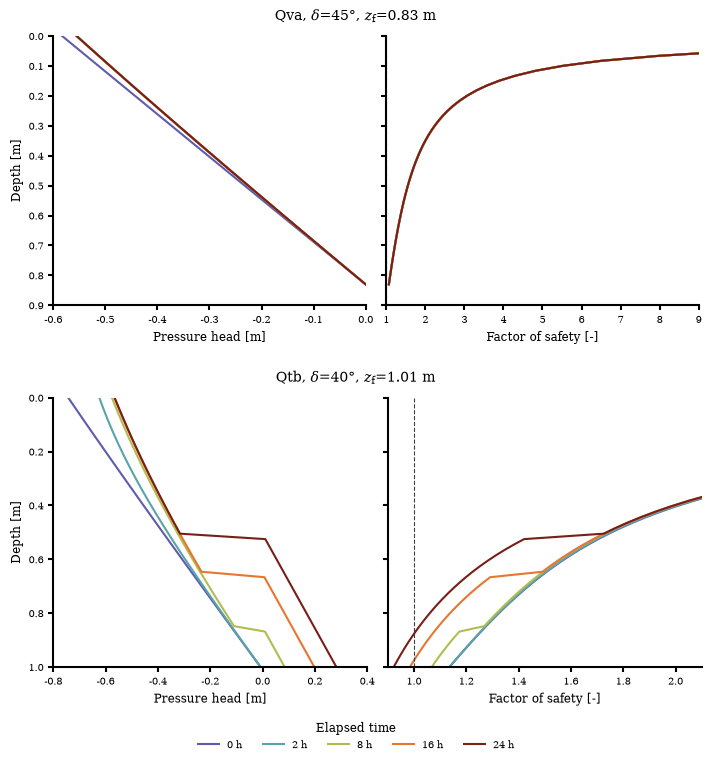

In [3]:
fig = plt.figure(figsize=(7.0, 7.5), constrained_layout=True)
row_figures = fig.subfigures(2, 1, hspace=0.05)
axes = np.empty((2, 2), dtype=object)

for row, (case, row_figure) in enumerate(zip(cases, row_figures)):
    axes[row] = row_figure.subplots(1, 2, sharey=True)
    row_figure.suptitle(
        case["name"] + rf", $\delta$={45 if row == 0 else 40}°, $z_{{\mathrm{{f}}}}$={case['depth_m']:.2f} m",
        fontsize=10,
    )
    result = case["result"]
    arrays = result.arrays()
    time_h = result.time
    for color, target_h in zip(selected_colors, selected_hours):
        idx = int(np.argmin(np.abs(time_h - target_h)))
        label = f"{time_h[idx]:g} h"
        axes[row, 0].plot(arrays["pressure_head_total"][idx], arrays["z"], color=color, label=label)
        axes[row, 1].plot(arrays["factor_of_safety"][idx], arrays["z"], color=color, label=label)
    axes[row, 0].set_ylabel("Depth [m]")
    for ax in axes[row]:
        ax.set_xlabel("Pressure head [m]" if ax is axes[row, 0] else "Factor of safety [-]")
    axes[row, 1].axvline(1.0, color="0.25", linestyle="--", linewidth=0.8)

axes[0, 0].set_ylim(0.9, 0.0)
axes[1, 0].set_ylim(1.0, 0.0)
axes[0, 0].set_xlim(-0.6, 0.0)
axes[1, 0].set_xlim(-0.8, 0.4)
axes[0, 1].set_xlim(1.0, 9.0)
axes[1, 1].set_xlim(0.9, 2.1)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=5, title="Elapsed time")

plt.show()


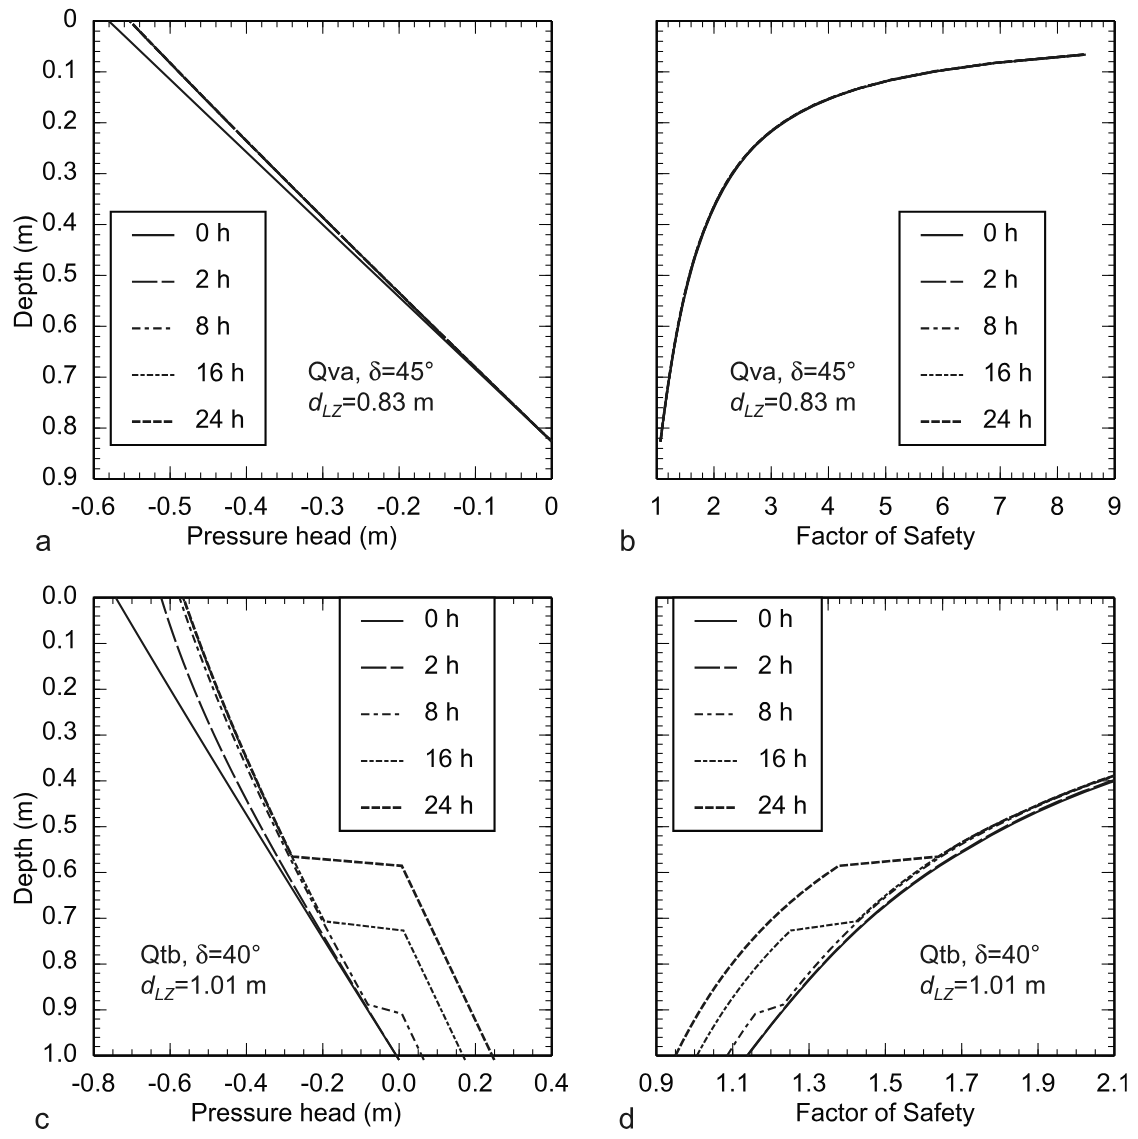

*Published reference: Baum et al. (2010), Figure 10. The image is shown separately from the calculated profiles.*


In [4]:
display(Image(filename=str(ASSET_DIR / "Figure_10_Baum_etal_2010.png"), width=700))
display(Markdown('*Published reference: Baum et al. (2010), Figure 10. The image is shown separately from the calculated profiles.*\n'))

## Quantitative checkpoints

The table below is computed from the same Qva and Qtb runs used in the profile comparison: 120 characteristic roots, 50 depth intervals, and hourly output from 0 to 24 h. It brings the published benchmarks into this notebook so that the figures and numerical summary share one setup.

Published initial and 24-hour factors of safety are approximate readings of Baum et al. (2010), Figure 10. The absolute difference is a comparison with that reading, not a measurement uncertainty. The first sampled FS ≤ 1 is an hourly checkpoint, not an interpolated continuous failure time. Maximum rise is relative to each case's initial water table.

The test suite separately checks Qva/Qtb responses and Qtb threshold timing, with its own numerical resolutions and tolerances. A code-to-code comparison is strongest when identical inputs, numerical controls, and raw reference outputs are available; the rasterized figure does not provide all of those. Refining depth and time sampling can change the reported endpoints and crossing time; see [numerical controls](/unsatstab/inputs-outputs/#numerical-controls).


In [5]:
from IPython.display import Markdown, display

published_fs = {"Qva": (1.06, 1.06), "Qtb": (1.13, 0.94)}
rows = [
    "| Case | Published initial FS | Computed initial FS | Published 24 h FS | Computed 24 h FS | Final absolute difference | First sampled FS ≤ 1 | Maximum rise [m] |",
    "| --- | ---: | ---: | ---: | ---: | ---: | --- | ---: |",
]
for case in cases:
    result = case["result"]
    fs = result.factor_of_safety_at_failure_plane
    initial_ref, final_ref = published_fs[case["name"]]
    crossings = np.flatnonzero(fs <= 1.0)
    first_crossing = f"{output_times_h[crossings[0]]:g} h" if crossings.size else "None"
    rows.append(
        f"| {case['name']} | {initial_ref:.2f} | {fs[0]:.3f} | "
        f"{final_ref:.2f} | {fs[-1]:.3f} | {abs(fs[-1] - final_ref):.3f} | "
        f"{first_crossing} | {result.water_table_rise.max():.3f} |"
    )
display(Markdown("\n".join(rows)))


| Case | Published initial FS | Computed initial FS | Published 24 h FS | Computed 24 h FS | Final absolute difference | First sampled FS ≤ 1 | Maximum rise [m] |
| --- | ---: | ---: | ---: | ---: | ---: | --- | ---: |
| Qva | 1.06 | 1.066 | 1.06 | 1.066 | 0.006 | None | 0.000 |
| Qtb | 1.13 | 1.127 | 0.94 | 0.917 | 0.023 | 14 h | 0.504 |

## What this verifies—and what it does not

The Qva response remains near its reference factor of safety. In Qtb, `unsatstab` reaches $\mathrm{FS}\leq1$ at the first sampled time of 14 h with the numerical controls used here, versus roughly 16 h read from the TRIGRS reference. At 24 h the computed factor of safety is about 0.92 versus a reference near 0.94.

These comparisons verify selected one-column responses. They do not validate site-specific predictions. In particular, this formulation does not include the deep saturated-zone pressure diffusion represented in TRIGRS, so users should treat post-water-table behavior as a documented model assumption.